In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv('heart.csv')

In [5]:
print("First 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nRandom 5 Rows:")
display(df.sample(min(5, len(df)), random_state=42))

print("\nDataset Shape:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn Names:")
print(df.columns.tolist())

First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Last 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0



Random 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1,0
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0
111,57,1,2,150,126,1,1,173,0,0.2,2,1,3,1
246,56,0,0,134,409,0,0,150,1,1.9,1,2,3,0
60,71,0,2,110,265,1,0,130,0,0.0,2,1,2,1



Dataset Shape:
Rows: 303
Columns: 14

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [4]:
df.shape

(303, 14)

In [6]:
print("Dataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

print("\nNumber of Unique Values Per Column:")
display(df.nunique().to_frame("Unique Values"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     floa

,Unique Values
age,41
sex,2
cp,4
trestbps,49
chol,152
fbs,2
restecg,3
thalach,91
exang,2
oldpeak,40


In [8]:
print("Numerical Feature Statistics:")
display(df.describe().T)

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [9]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing)

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Count,Missing Percentage
age,0,0.0
sex,0,0.0
cp,0,0.0
trestbps,0,0.0
chol,0,0.0
fbs,0,0.0
restecg,0,0.0
thalach,0,0.0
exang,0,0.0
oldpeak,0,0.0


Total Missing Values: 0


In [10]:
print("Number of Duplicate Rows:", df.duplicated().sum())

duplicates = df[df.duplicated(keep=False)]

if not duplicates.empty:
    display(duplicates)
else:
    print("No duplicate rows found.")

Number of Duplicate Rows: 1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [11]:
# Remove duplicate rows, keeping the first occurrence
df = df.drop_duplicates(keep="first").reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (302, 14)
Remaining duplicate rows: 0


In [ ]:
# Identify numerical and categorical features

numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Categorical Columns:
[]


Target Value Counts:


target
0    138
1    164
Name: count, dtype: int64


Target Percentage Distribution:


target
0    45.7
1    54.3
Name: proportion, dtype: float64

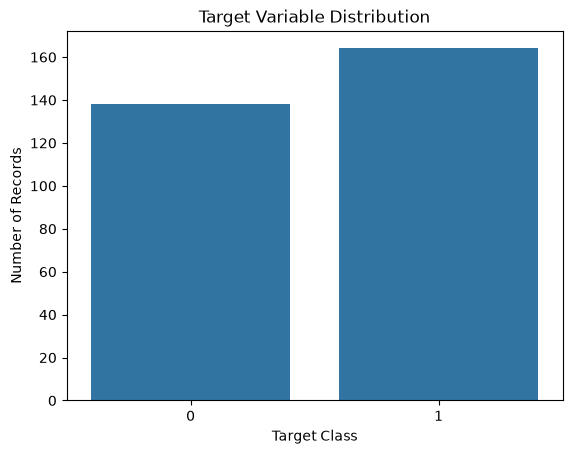

In [13]:
# Visualize the target variable distribution
target_col = "target"

print("Target Value Counts:")
display(df[target_col].value_counts().sort_index())

print("\nTarget Percentage Distribution:")
display(
    (df[target_col].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

sns.countplot(data=df, x=target_col)
plt.title("Target Variable Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.show()

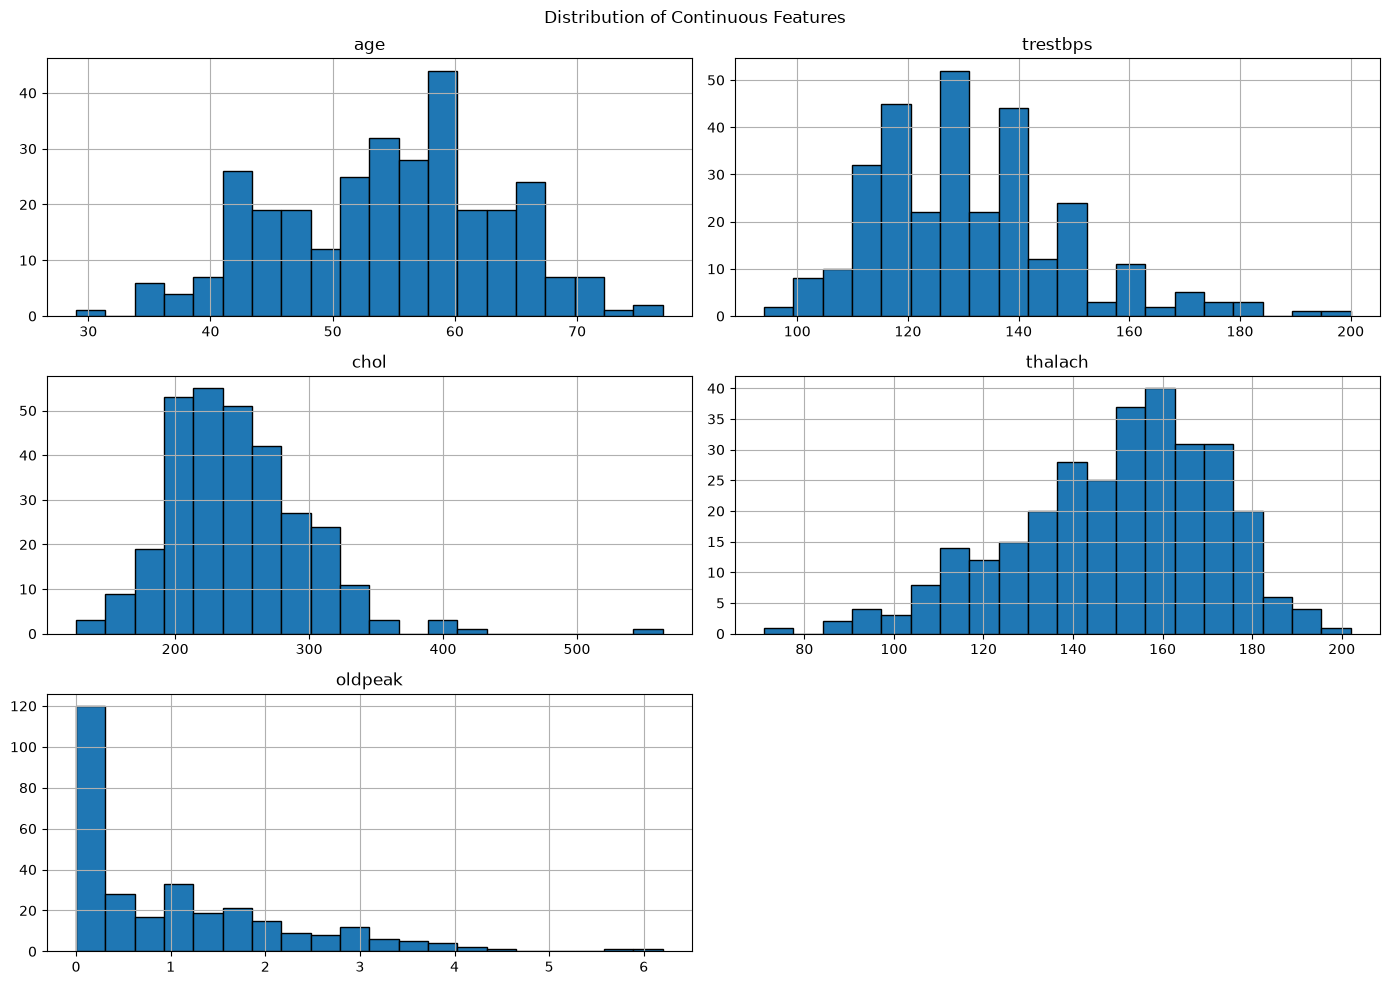

In [14]:
# Visualize the distribution of continuous features
continuous_features = [
    col for col in [
        "age", "trestbps", "chol", "thalach", "oldpeak"
    ]
    if col in df.columns
]

df[continuous_features].hist(
    bins=20,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle("Distribution of Continuous Features")
plt.tight_layout()
plt.show()


Value Counts for sex:


sex
0     96
1    206
Name: count, dtype: int64

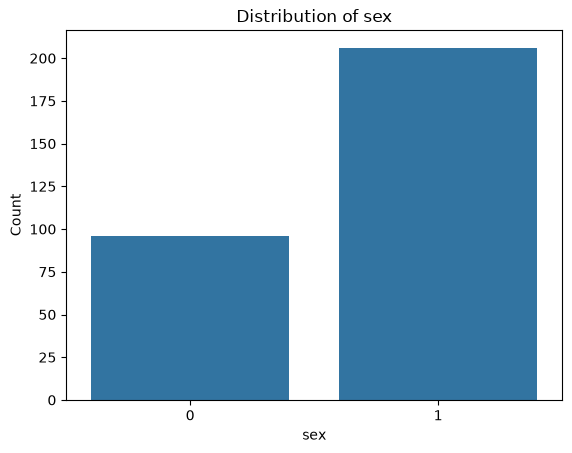


Value Counts for cp:


cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64

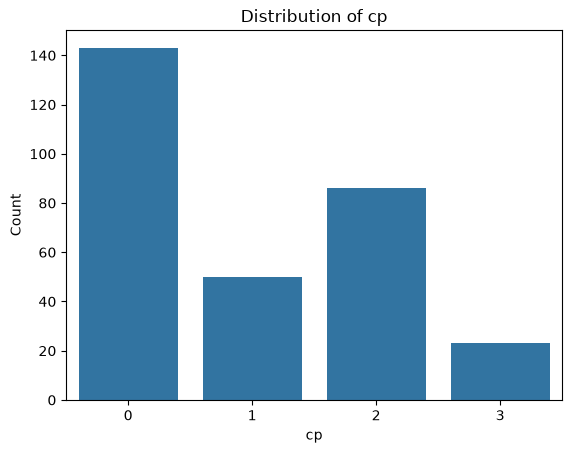


Value Counts for fbs:


fbs
0    257
1     45
Name: count, dtype: int64

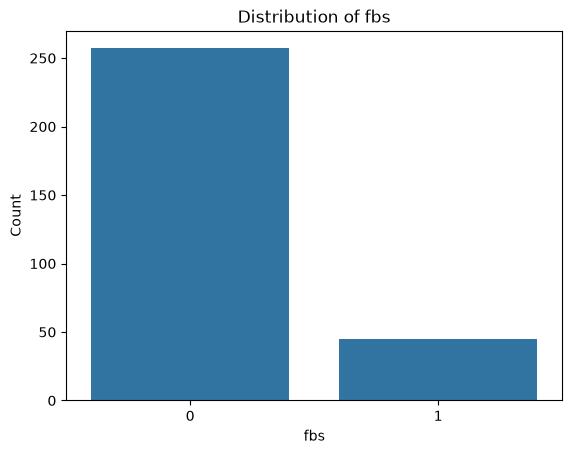


Value Counts for restecg:


restecg
0    147
1    151
2      4
Name: count, dtype: int64

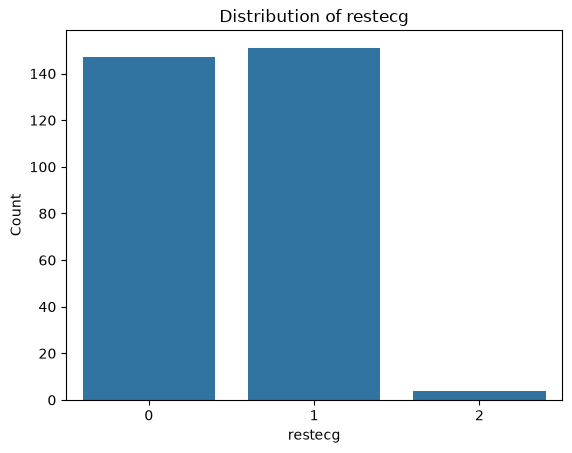


Value Counts for exang:


exang
0    203
1     99
Name: count, dtype: int64

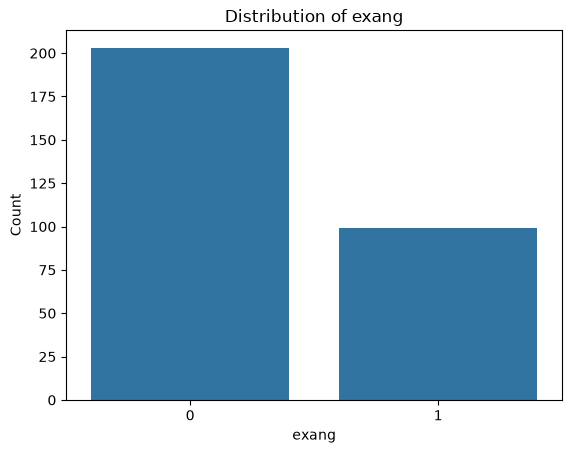


Value Counts for slope:


slope
0     21
1    140
2    141
Name: count, dtype: int64

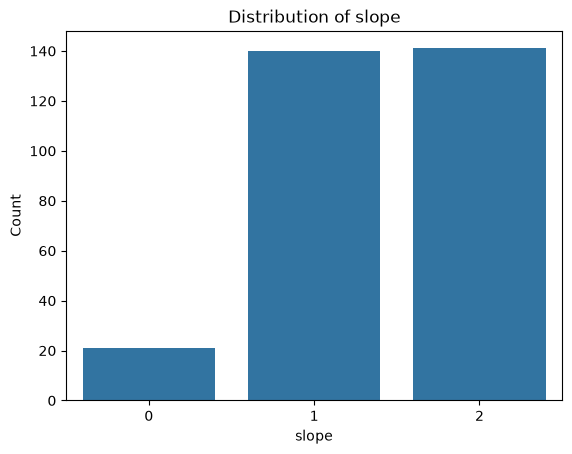


Value Counts for ca:


ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

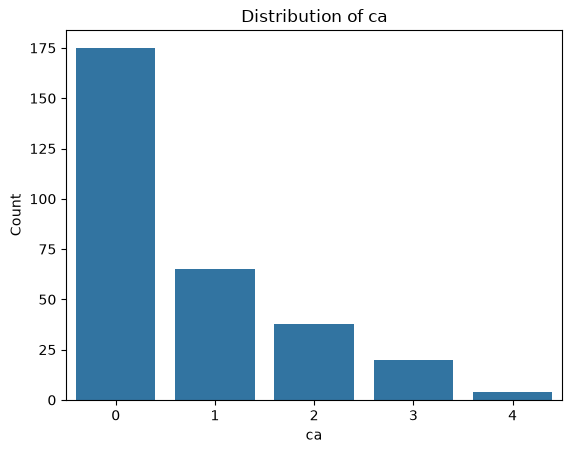


Value Counts for thal:


thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64

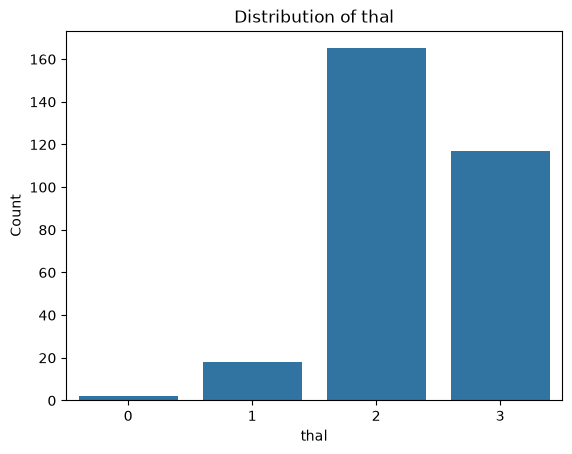

In [15]:
# Visualize the distribution of encoded categorical features
encoded_categorical_features = [
    col for col in [
        "sex", "cp", "fbs", "restecg",
        "exang", "slope", "ca", "thal"
    ]
    if col in df.columns
]

for col in encoded_categorical_features:
    print(f"\nValue Counts for {col}:")
    display(df[col].value_counts(dropna=False).sort_index())

    sns.countplot(data=df, x=col)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

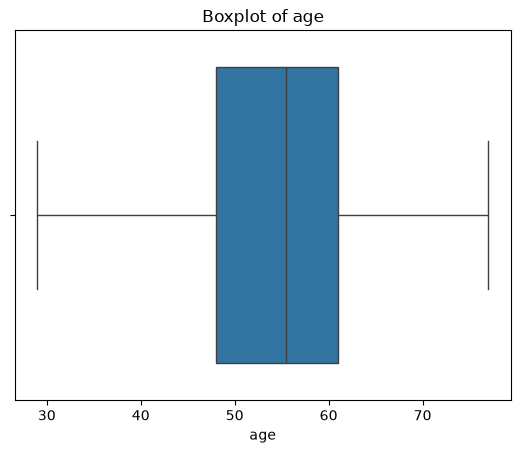

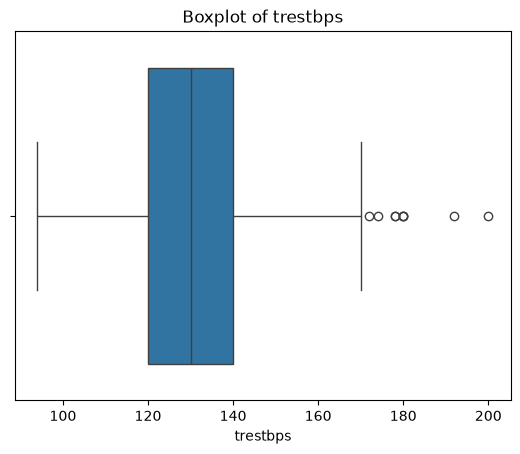

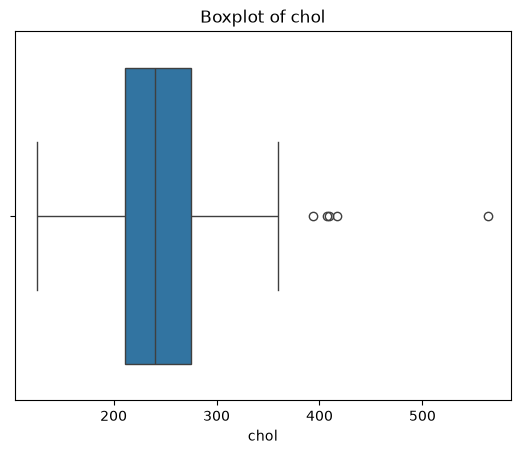

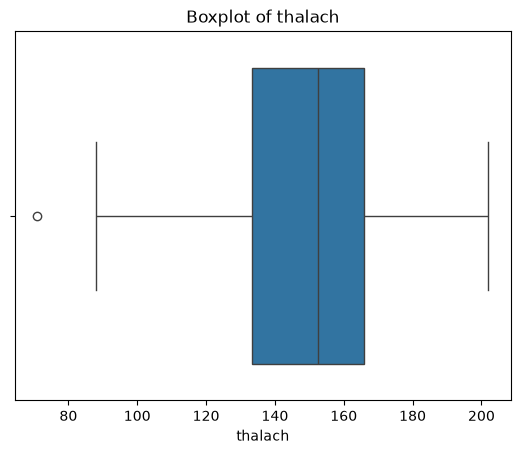

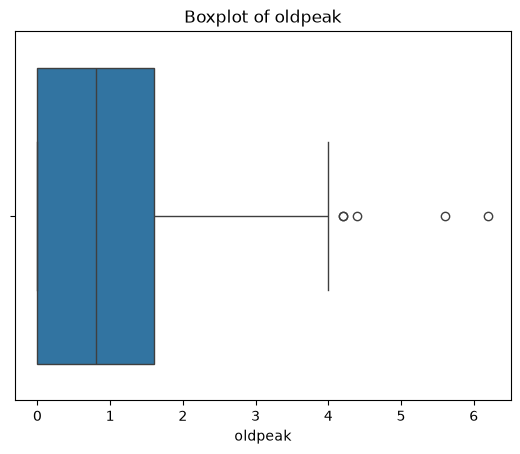

In [16]:
# Visualize boxplots for continuous features
for col in continuous_features:
    sns.boxplot(data=df, x=col)
    plt.title(f"Boxplot of {col}")
    plt.show()

In [17]:
# Summarize potential outliers for each continuous feature
outlier_summary = []

for col in continuous_features:
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": count
    })

display(pd.DataFrame(outlier_summary))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
0,age,48.00,61.00,13.00,28.500,80.500,0
1,trestbps,120.00,140.00,20.00,90.000,170.000,9
2,chol,211.00,274.75,63.75,115.375,370.375,5
3,thalach,133.25,166.00,32.75,84.125,215.125,1
4,oldpeak,0.00,1.60,1.60,-2.400,4.000,5


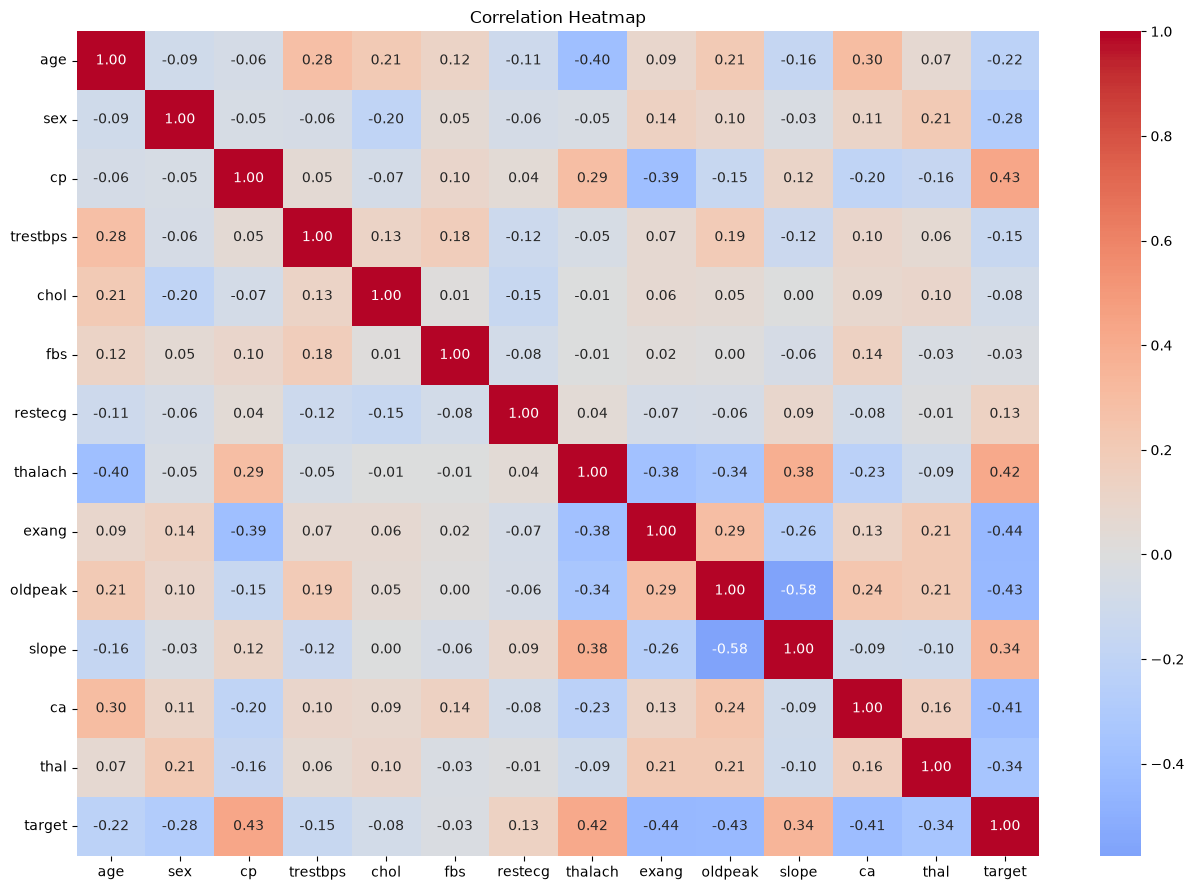

In [18]:
# Visualize the correlation heatmap for numerical features
correlation = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

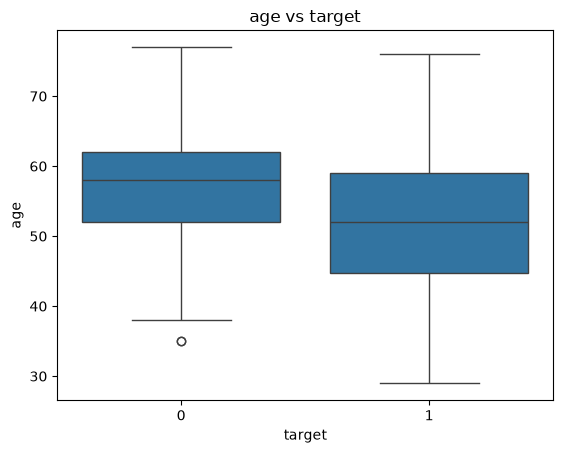

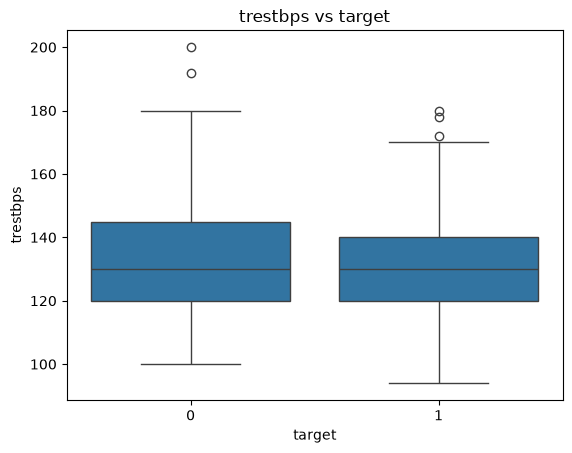

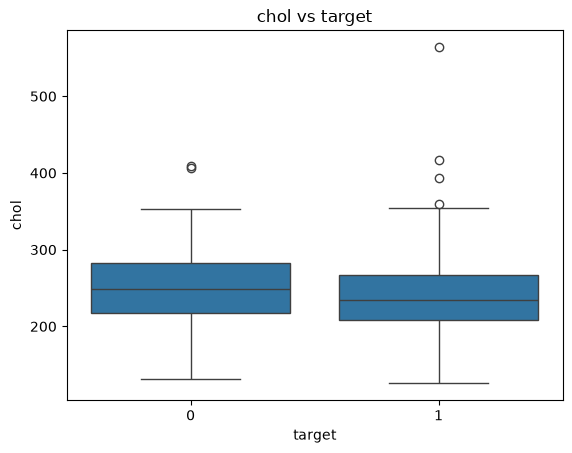

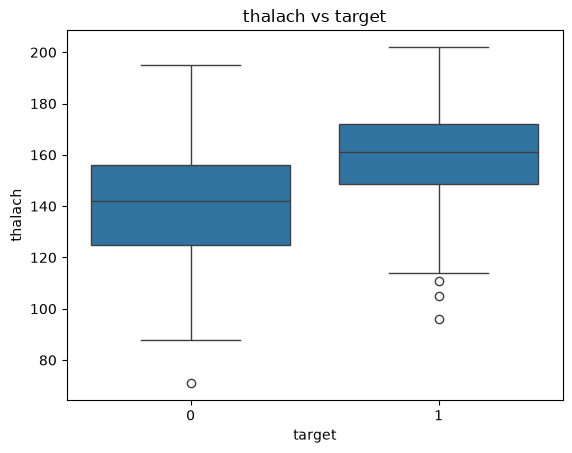

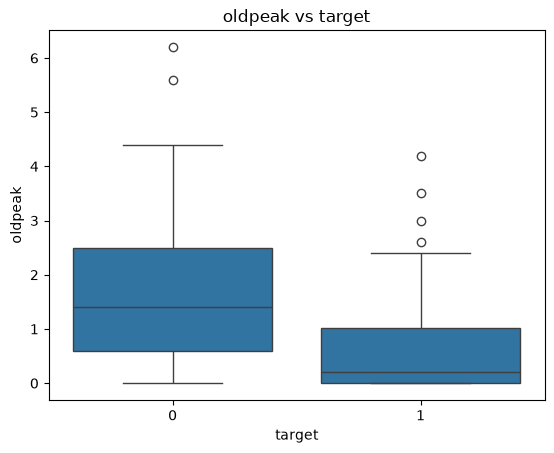

In [ ]:
# Visualize boxplots of continuous features against the target variable
for col in continuous_features:
    sns.boxplot(data=df, x=target_col, y=col)
    plt.title(f"{col} vs {target_col}")
    plt.show()


sex vs target (Row Percentages):


target,0,1
sex,,
0,25.00,75.00
1,55.34,44.66


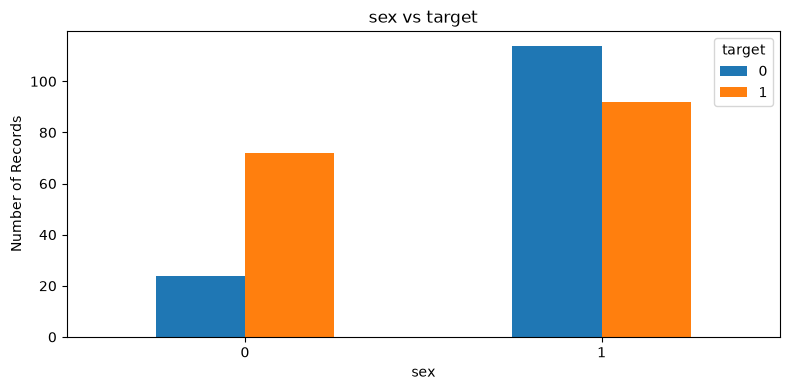


cp vs target (Row Percentages):


target,0,1
cp,,
0,72.73,27.27
1,18.00,82.00
2,20.93,79.07
3,30.43,69.57


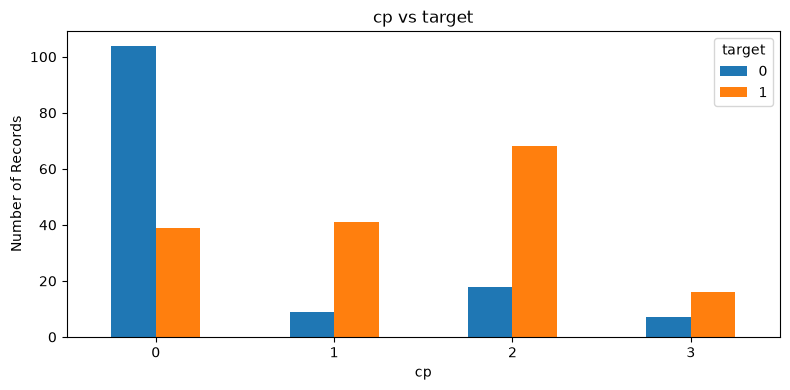


fbs vs target (Row Percentages):


target,0,1
fbs,,
0,45.14,54.86
1,48.89,51.11


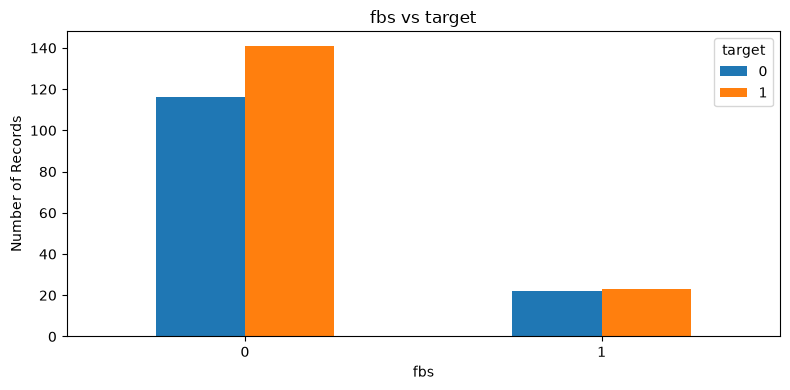


restecg vs target (Row Percentages):


target,0,1
restecg,,
0,53.74,46.26
1,37.09,62.91
2,75.00,25.00


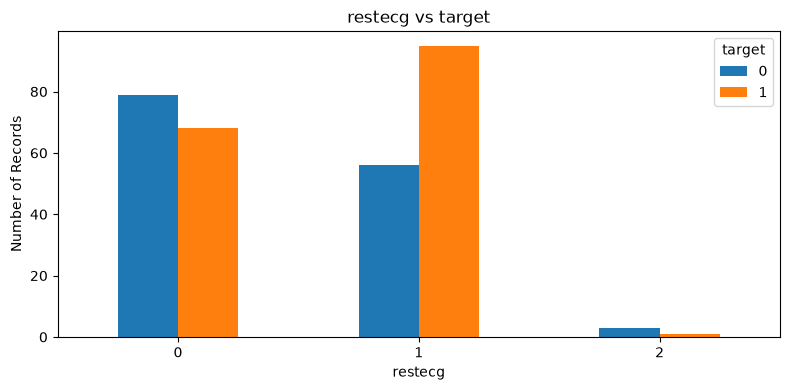


exang vs target (Row Percentages):


target,0,1
exang,,
0,30.54,69.46
1,76.77,23.23


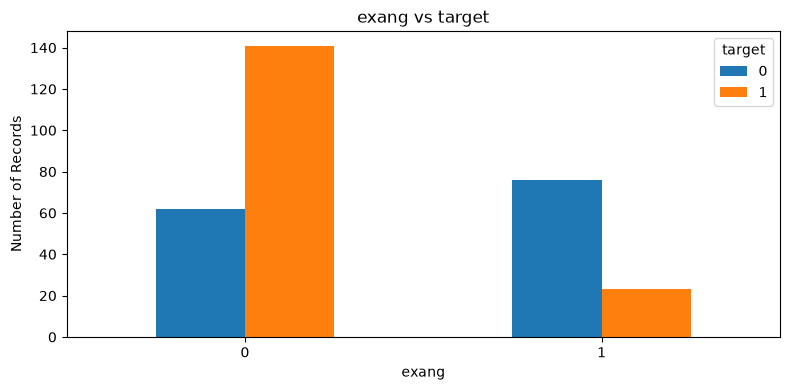


slope vs target (Row Percentages):


target,0,1
slope,,
0,57.14,42.86
1,65.00,35.00
2,24.82,75.18


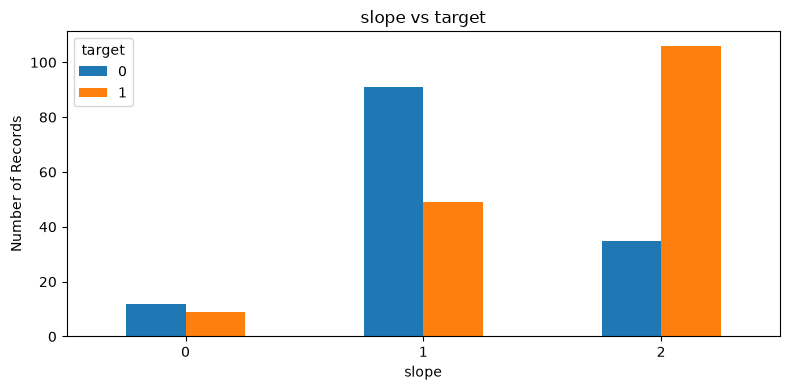


ca vs target (Row Percentages):


target,0,1
ca,,
0,25.71,74.29
1,67.69,32.31
2,81.58,18.42
3,85.00,15.00
4,25.00,75.00


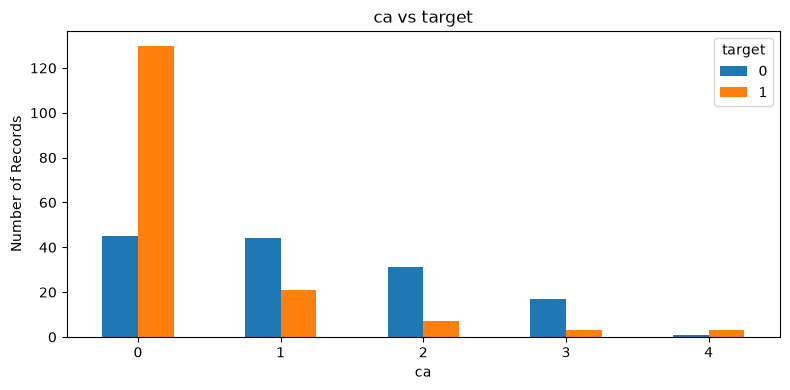


thal vs target (Row Percentages):


target,0,1
thal,,
0,50.00,50.00
1,66.67,33.33
2,21.82,78.18
3,76.07,23.93


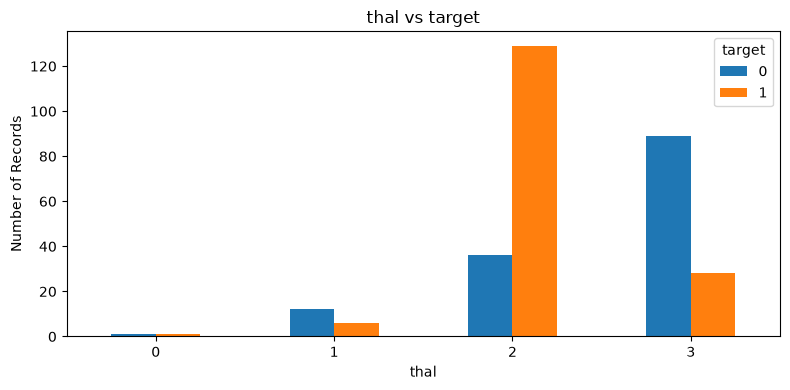

In [20]:
# Visualize cross-tabulations for encoded categorical features
for col in encoded_categorical_features:
    cross_tab = pd.crosstab(
        df[col],
        df[target_col],
        normalize="index"
    ) * 100

    print(f"\n{col} vs {target_col} (Row Percentages):")
    display(cross_tab.round(2))

    pd.crosstab(
        df[col],
        df[target_col]
    ).plot(kind="bar", figsize=(8, 4))

    plt.title(f"{col} vs {target_col}")
    plt.xlabel(col)
    plt.ylabel("Number of Records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [21]:
# Inspect ranges and unique values before deciding whether
# any values violate the dataset's documented definitions.

for col in df.columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min() if pd.api.types.is_numeric_dtype(df[col]) else "N/A")
    print("Maximum:", df[col].max() if pd.api.types.is_numeric_dtype(df[col]) else "N/A")
    print("Unique values:", df[col].nunique())


age
Minimum: 29
Maximum: 77
Unique values: 41

sex
Minimum: 0
Maximum: 1
Unique values: 2

cp
Minimum: 0
Maximum: 3
Unique values: 4

trestbps
Minimum: 94
Maximum: 200
Unique values: 49

chol
Minimum: 126
Maximum: 564
Unique values: 152

fbs
Minimum: 0
Maximum: 1
Unique values: 2

restecg
Minimum: 0
Maximum: 2
Unique values: 3

thalach
Minimum: 71
Maximum: 202
Unique values: 91

exang
Minimum: 0
Maximum: 1
Unique values: 2

oldpeak
Minimum: 0.0
Maximum: 6.2
Unique values: 40

slope
Minimum: 0
Maximum: 2
Unique values: 3

ca
Minimum: 0
Maximum: 4
Unique values: 5

thal
Minimum: 0
Maximum: 3
Unique values: 4

target
Minimum: 0
Maximum: 1
Unique values: 2


In [22]:
print("=" * 50)
print("EDA SUMMARY")
print("=" * 50)

print(f"Total Records: {df.shape[0]}")
print(f"Total Features/Columns: {df.shape[1]}")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")

print("\nData Types:")
print(df.dtypes.value_counts())

print("\nTarget Distribution:")
display(df[target_col].value_counts().sort_index())

print("\nTarget Distribution (%):")
display(
    (df[target_col].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

print("\nEDA Completed Successfully!")

EDA SUMMARY
Total Records: 302
Total Features/Columns: 14
Total Missing Values: 0
Total Duplicate Rows: 0

Data Types:
int64      13
float64     1
Name: count, dtype: int64

Target Distribution:


target
0    138
1    164
Name: count, dtype: int64


Target Distribution (%):


target
0    45.7
1    54.3
Name: proportion, dtype: float64


EDA Completed Successfully!


In [ ]:
X = df.iloc[:,0:-1] 
y = df.iloc[:,-1]

In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [25]:
print(X_train.shape)
print(X_test.shape)

(241, 13)
(61, 13)


In [26]:

rf = RandomForestClassifier()
gb = GradientBoostingClassifier()
svc = SVC()
lr = LogisticRegression()

In [34]:
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
rf_accuracy = accuracy_score(y_test,y_pred)
rf_accuracy

0.8852459016393442

In [36]:
gb.fit(X_train,y_train)
y_pred = gb.predict(X_test)
gb_accuracy = accuracy_score(y_test,y_pred)
gb_accuracy

0.8360655737704918

In [37]:
svc.fit(X_train,y_train)
y_pred = svc.predict(X_test)
svc_accuracy = accuracy_score(y_test,y_pred)
svc_accuracy

0.7049180327868853

In [38]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
lr_accuracy = accuracy_score(y_test,y_pred)
lr_accuracy

c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8524590163934426

In [40]:
# Summarize the accuracy of all models . Print the accuracy of each model in a dictionary format for easy comparison.
model_accuracies = {
    "Random Forest": rf_accuracy,
    "Gradient Boosting": gb_accuracy,
    "Support Vector Classifier": svc_accuracy,
    "Logistic Regression": lr_accuracy
}
print(model_accuracies)

{'Random Forest': 0.8852459016393442, 'Gradient Boosting': 0.8360655737704918, 'Support Vector Classifier': 0.7049180327868853, 'Logistic Regression': 0.8524590163934426}


In [41]:
rf = RandomForestClassifier(max_samples=0.75,random_state=42)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.8852459016393442

In [42]:
from sklearn.model_selection import cross_val_score
np.mean(cross_val_score(RandomForestClassifier(max_samples=0.75),X,y,cv=10,scoring='accuracy'))

np.float64(0.830967741935484)

###  GridSearchCV in Machine Learning

**GridSearchCV (Grid Search with Cross-Validation)** is a hyperparameter tuning technique in Machine Learning that finds the best combination of hyperparameters by testing all specified combinations and evaluating them using cross-validation.

**How it works:**
1. Define a model and a set of hyperparameter values.
2. Test every possible combination.
3. Evaluate each combination using cross-validation.
4. Select the combination with the best average validation score.

**Example:** In an SVM model, GridSearchCV can test different values of `C`, `kernel`, and `gamma` to find the best configuration.

**In simple words:** GridSearchCV automatically tries different model settings and selects the best-performing combination based on a chosen evaluation metric.

In [43]:
# Number of trees in random forest
n_estimators = [20,60,100,120]

# Number of features to consider at every split
max_features = [0.2,0.6,1.0]

# Maximum number of levels in tree
max_depth = [2,8,None]

# Number of samples
max_samples = [0.5,0.75,1.0]

# 108 diff random forest train

In [44]:
param_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
              'max_samples':max_samples
             }
print(param_grid)

{'n_estimators': [20, 60, 100, 120], 'max_features': [0.2, 0.6, 1.0], 'max_depth': [2, 8, None], 'max_samples': [0.5, 0.75, 1.0]}


In [45]:
rf = RandomForestClassifier()

In [ ]:
from sklearn.model_selection import GridSearchCV

rf_grid = GridSearchCV(estimator = rf,                       # estimator object
                       param_grid = param_grid,              # parameter grid is a dictionary of parameters to tune
                       cv = 5,                               # number of cross-validation folds
                       verbose=2,                            # verbosity level
                       n_jobs = -1)                          # number of parallel jobs

In [47]:
rf_grid.fit(X_train,y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 8, ...], 'max_features': [0.2, 0.6, ...], 'max_samples': [0.5, 0.75, ...], 'n_estimators': [20, 60, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_mod

In [48]:
rf_grid.best_params_

{'max_depth': 2, 'max_features': 0.6, 'max_samples': 1.0, 'n_estimators': 60}

In [49]:
rf_grid.best_score_

np.float64(0.8465986394557824)

In [50]:
# Initialize Random Forest with the given parameters
rf_model = RandomForestClassifier(
    max_depth=2,
    max_features=0.6,
    max_samples=1.0,
    n_estimators=60,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.8524590163934426


###  RandomizedSearchCV in Machine Learning

**RandomizedSearchCV** is a hyperparameter tuning technique that randomly selects a specified number of hyperparameter combinations from a given search space and evaluates them using cross-validation to find a good-performing configuration.

**How it works:**
1. Define the model and hyperparameter search space.
2. Specify the number of combinations to try using `n_iter`.
3. Randomly sample hyperparameter combinations.
4. Evaluate each combination using cross-validation.
5. Select the combination with the best average validation score.

**Example:** For a Random Forest model, RandomizedSearchCV can randomly test different values of `n_estimators`, `max_depth`, and `max_features` to identify an effective configuration.

**In simple words:** Instead of testing every possible combination like GridSearchCV, RandomizedSearchCV tests a limited number of randomly selected combinations, often saving time when the search space is large.

In [51]:
# Number of trees in random forest
n_estimators = [20,60,100,120]

# Number of features to consider at every split
max_features = [0.2,0.6,1.0]

# Maximum number of levels in tree
max_depth = [2,8,None]

# Number of samples
max_samples = [0.5,0.75,1.0]

# Bootstrap samples
bootstrap = [True,False]

# Minimum number of samples required to split a node
min_samples_split = [2, 5]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2]

In [52]:
param_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
              'max_samples':max_samples,
              'bootstrap':bootstrap,
              'min_samples_split':min_samples_split,
              'min_samples_leaf':min_samples_leaf
             }
print(param_grid)

{'n_estimators': [20, 60, 100, 120], 'max_features': [0.2, 0.6, 1.0], 'max_depth': [2, 8, None], 'max_samples': [0.5, 0.75, 1.0], 'bootstrap': [True, False], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}


In [53]:
from sklearn.model_selection import RandomizedSearchCV

rf_grid = RandomizedSearchCV(estimator = rf, 
                       param_distributions = param_grid, 
                       cv = 5, 
                       verbose=2, 
                       n_jobs = -1)

In [54]:
rf_grid.fit(X_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
35 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
35 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py", line 412, in fit
    raise ValueError(
   

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True, False], 'max_depth': [2, 8, ...], 'max_features': [0.2, 0.6, ...], 'max_samples': [0.5, 0.75, ...], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` 

In [55]:
rf_grid.best_params_

{'n_estimators': 120,
 'min_samples_split': 5,
 'min_samples_leaf': 2,
 'max_samples': 0.5,
 'max_features': 0.2,
 'max_depth': None,
 'bootstrap': True}

In [56]:
rf_grid.best_score_

np.float64(0.8423469387755101)